# Exploratory Data Analysis - Crop Recommendation

**Goal:** understand the dataset before building any model.

The dataset has soil nutrient readings (N, P, K), weather readings (temperature, humidity, rainfall),
soil pH, and the crop best suited to those conditions (`label`).

What this notebook covers:
1. Loading the data and first look
2. Data quality: missing values, duplicates, invalid values
3. Descriptive statistics
4. Target (crop) distribution
5. Feature distributions (histograms, boxplots, outliers)
6. Correlation between features
7. How features differ across crops

> The original CSV is only **read**, never changed. All charts are saved to `results/figures/`.

## 0. Setup
Import libraries, set paths and a consistent chart style.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Paths are relative to this notebook (notebooks/ folder)
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = PROJECT_ROOT / "data" / "Crop_recommendation.csv"
FIG_DIR = PROJECT_ROOT / "results" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
pd.set_option("display.precision", 2)

def save_fig(fig, name):
    """Save a figure to results/figures/ as PNG."""
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path, dpi=120, bbox_inches="tight")
    print(f"Saved: {path.relative_to(PROJECT_ROOT)}")

print("Data file:", DATA_PATH, "| exists:", DATA_PATH.exists())

Data file: c:\Users\sugit\OneDrive\Tài liệu\Crop-Recommendation-ML\data\Crop_recommendation.csv | exists: True


## 1. Load data and first look
We check how many rows and columns there are, column names, data types, and a few sample rows.

In [2]:
df = pd.read_csv(DATA_PATH)
print("Shape (rows, columns):", df.shape)
print("Columns:", list(df.columns))

Shape (rows, columns): (2200, 8)
Columns: ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label']


In [3]:
df.head()

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.88,82.00,6.50,202.94,rice
1,85,58,41,21.77,80.32,7.04,226.66,rice
2,60,55,44,23.00,82.32,7.84,263.96,rice
3,74,35,40,26.49,80.16,6.98,242.86,rice
4,78,42,42,20.13,81.60,7.63,262.72,rice


In [4]:
df.sample(5, random_state=42)

,N,P,K,temperature,humidity,ph,rainfall,label
1451,101,17,47,29.49,94.73,6.19,26.31,muskmelon
1334,98,8,51,26.18,86.52,6.26,49.43,watermelon
1761,59,62,49,43.36,93.35,6.94,114.78,papaya
1735,44,60,55,34.28,90.56,6.83,98.54,papaya
1576,30,137,200,22.91,90.70,5.60,118.60,apple


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   str    
dtypes: float64(4), int64(3), str(1)
memory usage: 153.0 KB


In [6]:
FEATURES = ["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]
TARGET = "label"
df.dtypes.to_frame("dtype")

,dtype
N,int64
P,int64
K,int64
temperature,float64
humidity,float64
ph,float64
rainfall,float64
label,str


**Observation:** 7 numeric input features (N, P, K are whole numbers; the rest are decimals)
and 1 text column `label` - the crop name we will later predict. This is a **multi-class classification** problem.

## 2. Data quality checks
Real data can have gaps, repeats, or impossible values. Let's check:
- **Missing values** - empty cells
- **Duplicates** - identical rows
- **Invalid values** - values outside physical limits (e.g. negative nutrients, humidity > 100 %, pH outside 0-14)

In [7]:
missing = df.isna().sum().to_frame("missing_count")
missing["missing_pct"] = (missing["missing_count"] / len(df) * 100).round(2)
missing

,missing_count,missing_pct
N,0,0.0
P,0,0.0
K,0,0.0
temperature,0,0.0
humidity,0,0.0
ph,0,0.0
rainfall,0,0.0
label,0,0.0


In [8]:
print("Fully duplicated rows:", df.duplicated().sum())
print("Duplicated feature rows (same inputs, any label):", df.duplicated(subset=FEATURES).sum())

Fully duplicated rows: 0
Duplicated feature rows (same inputs, any label): 0


In [9]:
# Physical / domain validity rules
checks = {
    "N < 0": (df["N"] < 0).sum(),
    "P < 0": (df["P"] < 0).sum(),
    "K < 0": (df["K"] < 0).sum(),
    "humidity < 0 or > 100": ((df["humidity"] < 0) | (df["humidity"] > 100)).sum(),
    "ph < 0 or > 14": ((df["ph"] < 0) | (df["ph"] > 14)).sum(),
    "rainfall < 0": (df["rainfall"] < 0).sum(),
    "temperature < -10 or > 60 (unrealistic for crops)": ((df["temperature"] < -10) | (df["temperature"] > 60)).sum(),
}
pd.Series(checks, name="rows_failing").to_frame()

,rows_failing
N < 0,0
P < 0,0
K < 0,0
humidity < 0 or > 100,0
ph < 0 or > 14,0
rainfall < 0,0
temperature < -10 or > 60 (unrealistic for crops),0


In [10]:
# Suspicious-but-possible values worth a look
print("Rows with N == 0:", (df["N"] == 0).sum())
print("Rows with strongly acidic soil (ph < 4):", (df["ph"] < 4).sum())
print("Rows with strongly alkaline soil (ph > 9):", (df["ph"] > 9).sum())
print("Rows with very low humidity (< 20%):", (df["humidity"] < 20).sum())

Rows with N == 0: 27
Rows with strongly acidic soil (ph < 4): 10
Rows with strongly alkaline soil (ph > 9): 11
Rows with very low humidity (< 20%): 128


In [11]:
# Label text consistency: hidden spaces or mixed case would create fake extra classes
labels = df[TARGET]
print("Unique labels:", labels.nunique())
print("Labels with leading/trailing spaces:", (labels != labels.str.strip()).sum())
print("Labels not lowercase:", (labels != labels.str.lower()).sum())

Unique labels:

 22
Labels with leading/trailing spaces: 0
Labels not lowercase: 0


In [12]:
ranges = df[FEATURES].agg(["min", "max"]).T
ranges["range"] = ranges["max"] - ranges["min"]
ranges

,min,max,range
N,0.00,140.00,140.00
P,5.00,145.00,140.00
K,5.00,205.00,200.00
temperature,8.83,43.68,34.85
humidity,14.26,99.98,85.72
ph,3.50,9.94,6.43
rainfall,20.21,298.56,278.35


**Observation:** No missing values, no duplicates, no physically impossible values, and clean label text.
Some values (N = 0, pH below 4 or above 9, humidity under 20 %) are unusual but agronomically plausible,
so they are **kept**, not treated as errors.

Feature ranges are very different (pH ~3.5-10 vs. K ~5-205 vs. rainfall ~20-300). This matters for
scale-sensitive models (see recommendations at the end).

## 3. Descriptive statistics
Mean, standard deviation, quartiles and extremes for each feature, plus **skewness**
(0 = symmetric, positive = long right tail, negative = long left tail).

In [13]:
desc = df[FEATURES].describe().T
desc["median"] = df[FEATURES].median()
desc["skew"] = df[FEATURES].skew()
desc["kurtosis"] = df[FEATURES].kurt()
desc

,count,mean,std,min,25%,50%,75%,max,median,skew,kurtosis
N,2200.0,50.55,36.92,0.00,21.00,37.00,84.25,140.00,37.00,0.51,-1.06
P,2200.0,53.36,32.99,5.00,28.00,51.00,68.00,145.00,51.00,1.01,0.86
K,2200.0,48.15,50.65,5.00,20.00,32.00,49.00,205.00,32.00,2.38,4.45
temperature,2200.0,25.62,5.06,8.83,22.77,25.60,28.56,43.68,25.60,0.18,1.23
humidity,2200.0,71.48,22.26,14.26,60.26,80.47,89.95,99.98,80.47,-1.09,0.30
ph,2200.0,6.47,0.77,3.50,5.97,6.43,6.92,9.94,6.43,0.28,1.66
rainfall,2200.0,103.46,54.96,20.21,64.55,94.87,124.27,298.56,94.87,0.97,0.61


**Observation:**
- **K** is strongly right-skewed (skew > 2): most values are small, a few are very large.
- **P** and **rainfall** are moderately right-skewed.
- **humidity** is left-skewed: most rows are humid (median ~80 %), with a tail of dry rows.
- **temperature** and **pH** are close to symmetric.

## 4. Target variable: crop distribution
How many samples does each crop have? An unbalanced target can bias a model toward common classes.

In [14]:
counts = df[TARGET].value_counts()
crop_table = pd.DataFrame({"count": counts, "percent": (counts / len(df) * 100).round(2)})
print("Number of crops:", len(crop_table))
crop_table

Number of crops: 22


,count,percent
label,,
rice,100,4.55
maize,100,4.55
chickpea,100,4.55
kidneybeans,100,4.55
pigeonpeas,100,4.55
mothbeans,100,4.55
mungbean,100,4.55
blackgram,100,4.55
lentil,100,4.55


Saved: results\figures\01_crop_distribution.png


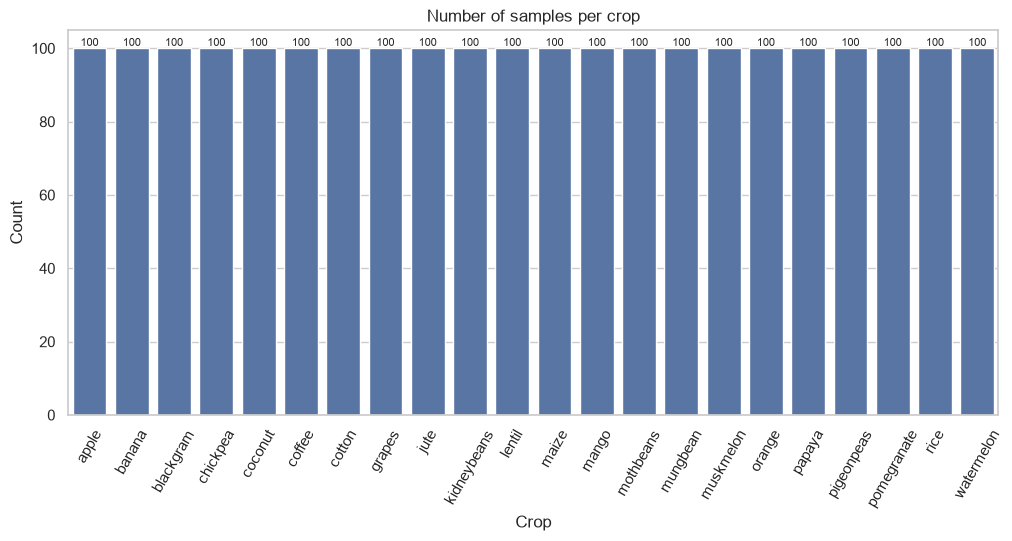

In [15]:
fig, ax = plt.subplots(figsize=(12, 5))
order = counts.sort_index().index
sns.countplot(data=df, x=TARGET, order=order, color="#4C72B0", ax=ax)
ax.set_title("Number of samples per crop")
ax.set_xlabel("Crop")
ax.set_ylabel("Count")
ax.tick_params(axis="x", rotation=60)
for c in ax.containers:
    ax.bar_label(c, fontsize=8)
save_fig(fig, "01_crop_distribution")
plt.show()

**Observation:** 22 crops, each with exactly **100 samples (4.55 %)**. The dataset is **perfectly balanced**,
so plain accuracy is a fair metric and no resampling (over/under-sampling) is needed.

## 5. Feature distributions
### 5.1 Histograms
Histograms show the shape of each feature. The smooth line is a density estimate.

Saved: results\figures\02_feature_histograms.png


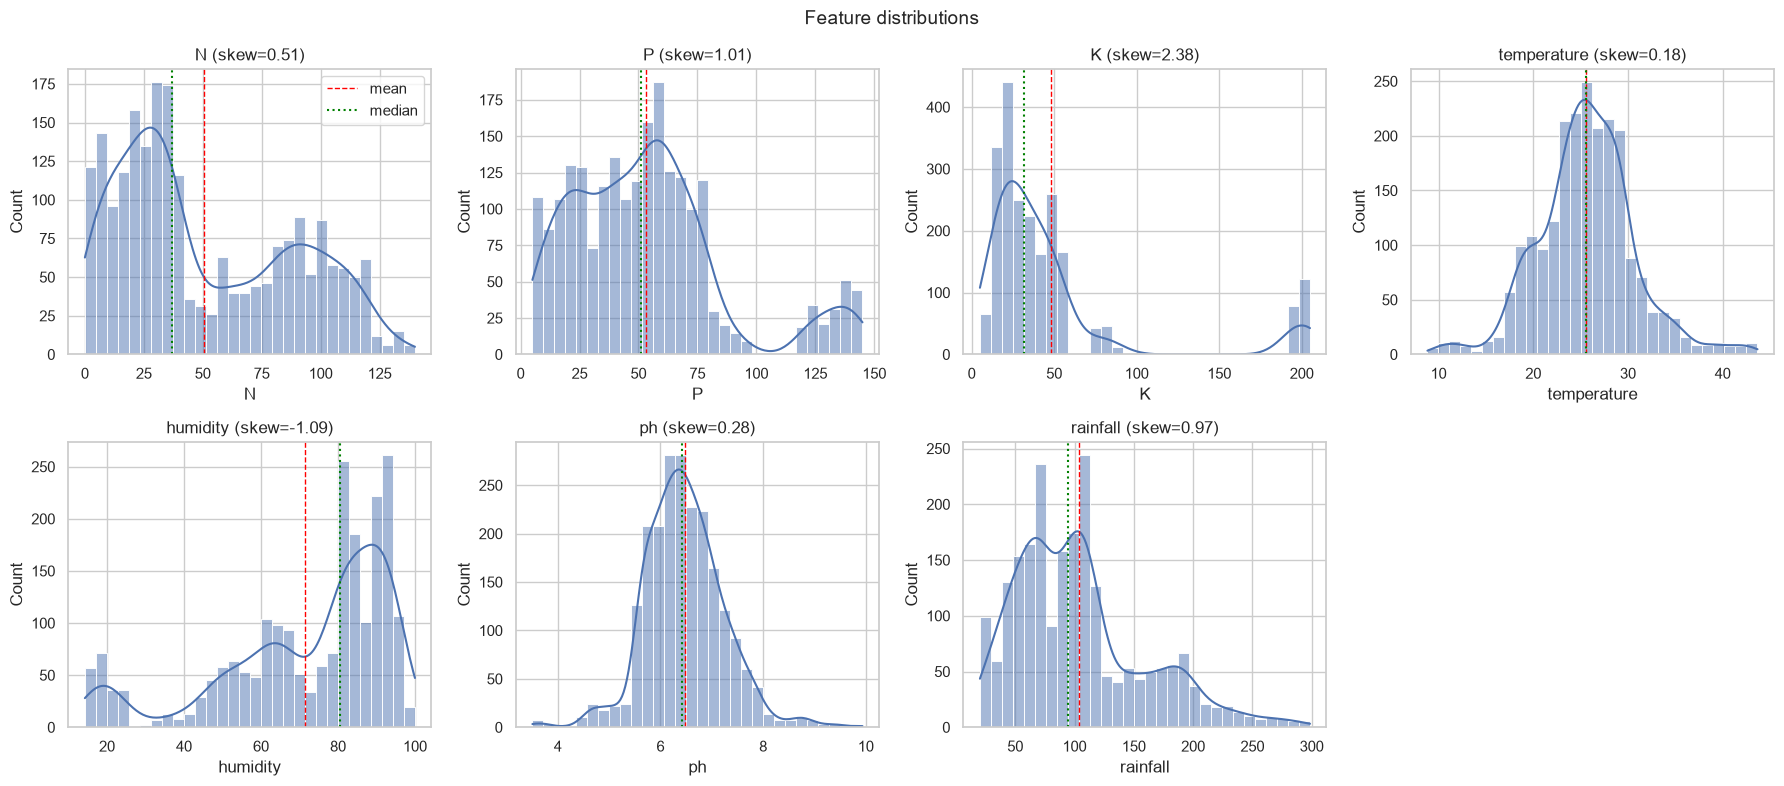

In [16]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, FEATURES):
    sns.histplot(df[col], kde=True, bins=30, ax=ax, color="#4C72B0")
    ax.axvline(df[col].mean(), color="red", ls="--", lw=1, label="mean")
    ax.axvline(df[col].median(), color="green", ls=":", lw=1.5, label="median")
    ax.set_title(f"{col} (skew={df[col].skew():.2f})")
axes.flat[0].legend()
axes.flat[-1].axis("off")
fig.suptitle("Feature distributions", fontsize=14)
fig.tight_layout()
save_fig(fig, "02_feature_histograms")
plt.show()

**Observation:** Several features are **multi-modal** (several peaks) - e.g. N, P and K.
That usually means different crop groups need very different conditions, which is good news for classification.
K and P show a separate cluster at very high values (~130-205).

### 5.2 Boxplots and outliers
A boxplot shows the median (middle line), the middle 50 % of data (box), and points beyond
1.5 × IQR (interquartile range) as potential **outliers**.

Saved: results\figures\03_feature_boxplots.png


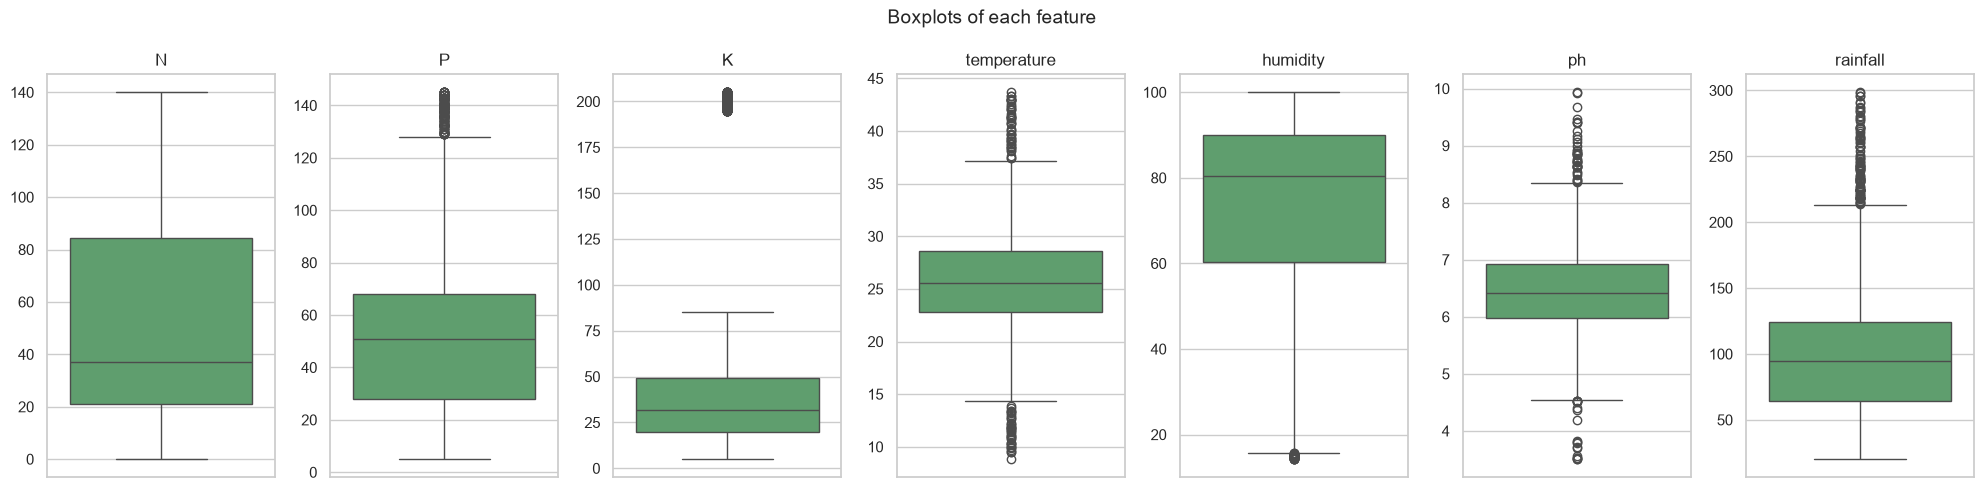

In [17]:
fig, axes = plt.subplots(1, 7, figsize=(20, 5))
for ax, col in zip(axes, FEATURES):
    sns.boxplot(y=df[col], ax=ax, color="#55A868")
    ax.set_title(col)
    ax.set_ylabel("")
fig.suptitle("Boxplots of each feature", fontsize=14)
fig.tight_layout()
save_fig(fig, "03_feature_boxplots")
plt.show()

In [18]:
def iqr_outlier_mask(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)

outlier_summary = pd.DataFrame({
    "outliers": {c: iqr_outlier_mask(df[c]).sum() for c in FEATURES},
})
outlier_summary["percent"] = (outlier_summary["outliers"] / len(df) * 100).round(2)
outlier_summary["crops_involved"] = {
    c: ", ".join(df.loc[iqr_outlier_mask(df[c]), TARGET].value_counts().index[:5]) for c in FEATURES
}
outlier_summary

,outliers,percent,crops_involved
N,0,0.00,
P,138,6.27,"apple, grapes"
K,200,9.09,"grapes, apple"
temperature,86,3.91,"papaya, grapes, orange"
humidity,30,1.36,chickpea
ph,57,2.59,"mothbeans, chickpea, mango"
rainfall,100,4.55,"rice, papaya, coconut"


**Observation:** The "outliers" are **not errors** - they belong to specific crops.
For example, every K outlier comes from **apple** and **grapes** (which need ~200 K), and
rainfall outliers come mostly from **rice** (very high rainfall). Removing them would delete
whole crops' natural patterns, so outliers should be **kept**.

## 6. Correlation between features
Correlation (from -1 to +1) tells us whether two features move together.
Very high correlation (|r| > 0.8) can mean redundant features.

Saved: results\figures\04_correlation_heatmap.png


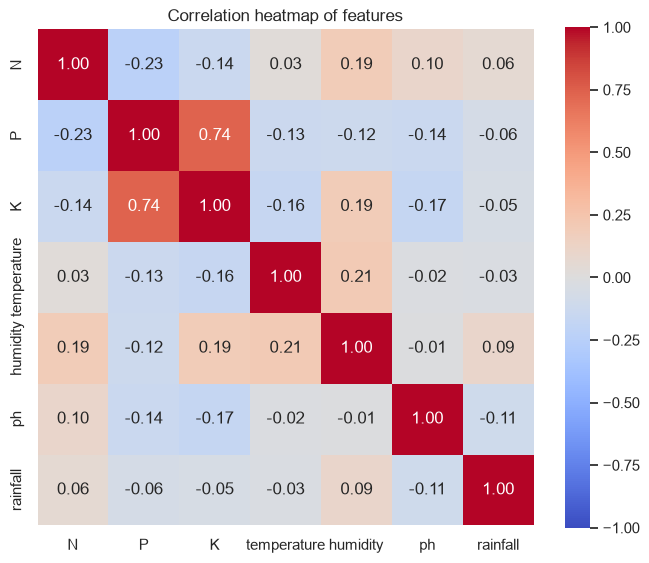

In [19]:
corr = df[FEATURES].corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Correlation heatmap of features")
save_fig(fig, "04_correlation_heatmap")
plt.show()

In [20]:
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
             .stack().rename("r").reset_index()
             .rename(columns={"level_0": "feature_1", "level_1": "feature_2"}))
pairs["abs_r"] = pairs["r"].abs()
pairs.sort_values("abs_r", ascending=False).head(5)

,feature_1,feature_2,r,abs_r
9,P,K,0.74,0.74
1,N,P,-0.23,0.23
25,temperature,humidity,0.21,0.21
18,K,humidity,0.19,0.19
4,N,humidity,0.19,0.19


**Observation:** Only **P and K** are strongly related (r ≈ 0.74), mainly because apple and grapes
have very high values of both. All other pairs are weak (|r| < 0.25). No feature is redundant enough
to drop.

## 7. How features differ across crops
This is the most useful part for the model: if crops have different "fingerprints" of conditions,
a classifier can learn to tell them apart.

### 7.1 Average conditions per crop

In [21]:
crop_means = df.groupby(TARGET)[FEATURES].mean().round(1)
crop_means

,N,P,K,temperature,humidity,ph,rainfall
label,,,,,,,
apple,20.8,134.2,199.9,22.6,92.3,5.9,112.7
banana,100.2,82.0,50.0,27.4,80.4,6.0,104.6
blackgram,40.0,67.5,19.2,30.0,65.1,7.1,67.9
chickpea,40.1,67.8,79.9,18.9,16.9,7.3,80.1
coconut,22.0,16.9,30.6,27.4,94.8,6.0,175.7
coffee,101.2,28.7,29.9,25.5,58.9,6.8,158.1
cotton,117.8,46.2,19.6,24.0,79.8,6.9,80.4
grapes,23.2,132.5,200.1,23.8,81.9,6.0,69.6
jute,78.4,46.9,40.0,25.0,79.6,6.7,174.8


Saved: results\figures\05_crop_feature_means_heatmap.png


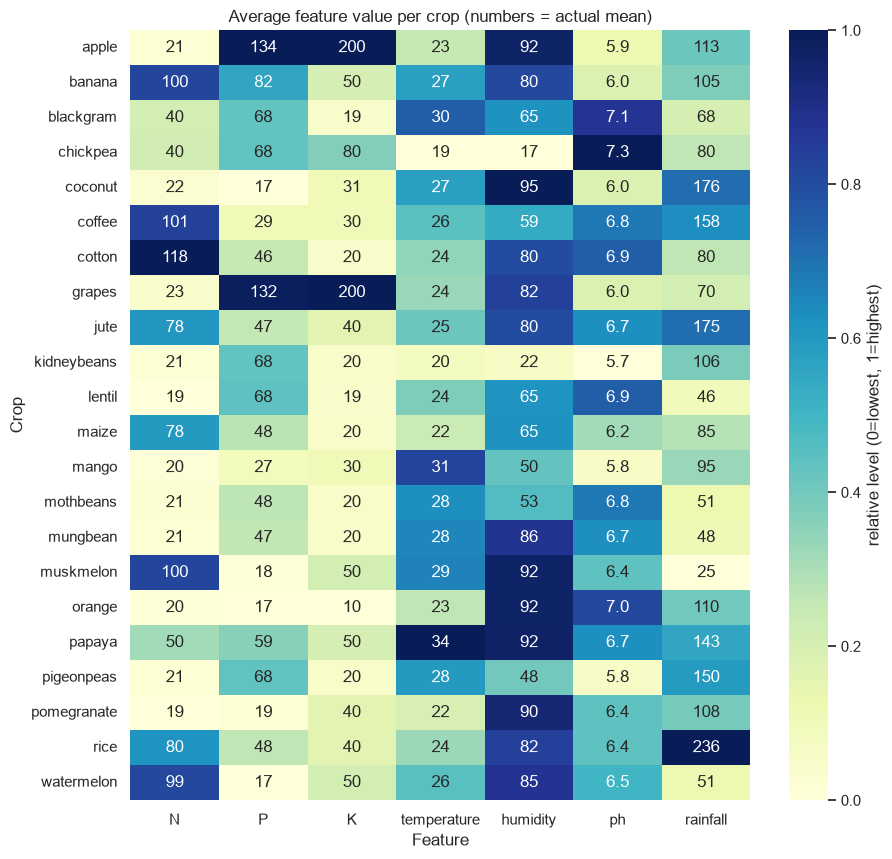

In [22]:
# Scale each column 0-1 so features with different units can share one colour scale
norm_means = (crop_means - crop_means.min()) / (crop_means.max() - crop_means.min())
fig, ax = plt.subplots(figsize=(10, 10))
annot = crop_means.apply(lambda s: s.map(("{:.1f}" if s.name == "ph" else "{:.0f}").format))
sns.heatmap(norm_means, annot=annot, fmt="", cmap="YlGnBu", cbar_kws={"label": "relative level (0=lowest, 1=highest)"}, ax=ax)
ax.set_title("Average feature value per crop (numbers = actual mean)")
ax.set_xlabel("Feature")
ax.set_ylabel("Crop")
save_fig(fig, "05_crop_feature_means_heatmap")
plt.show()

### 7.2 Feature distribution per crop (boxplots)

Saved: results\figures\06_features_by_crop_boxplots.png


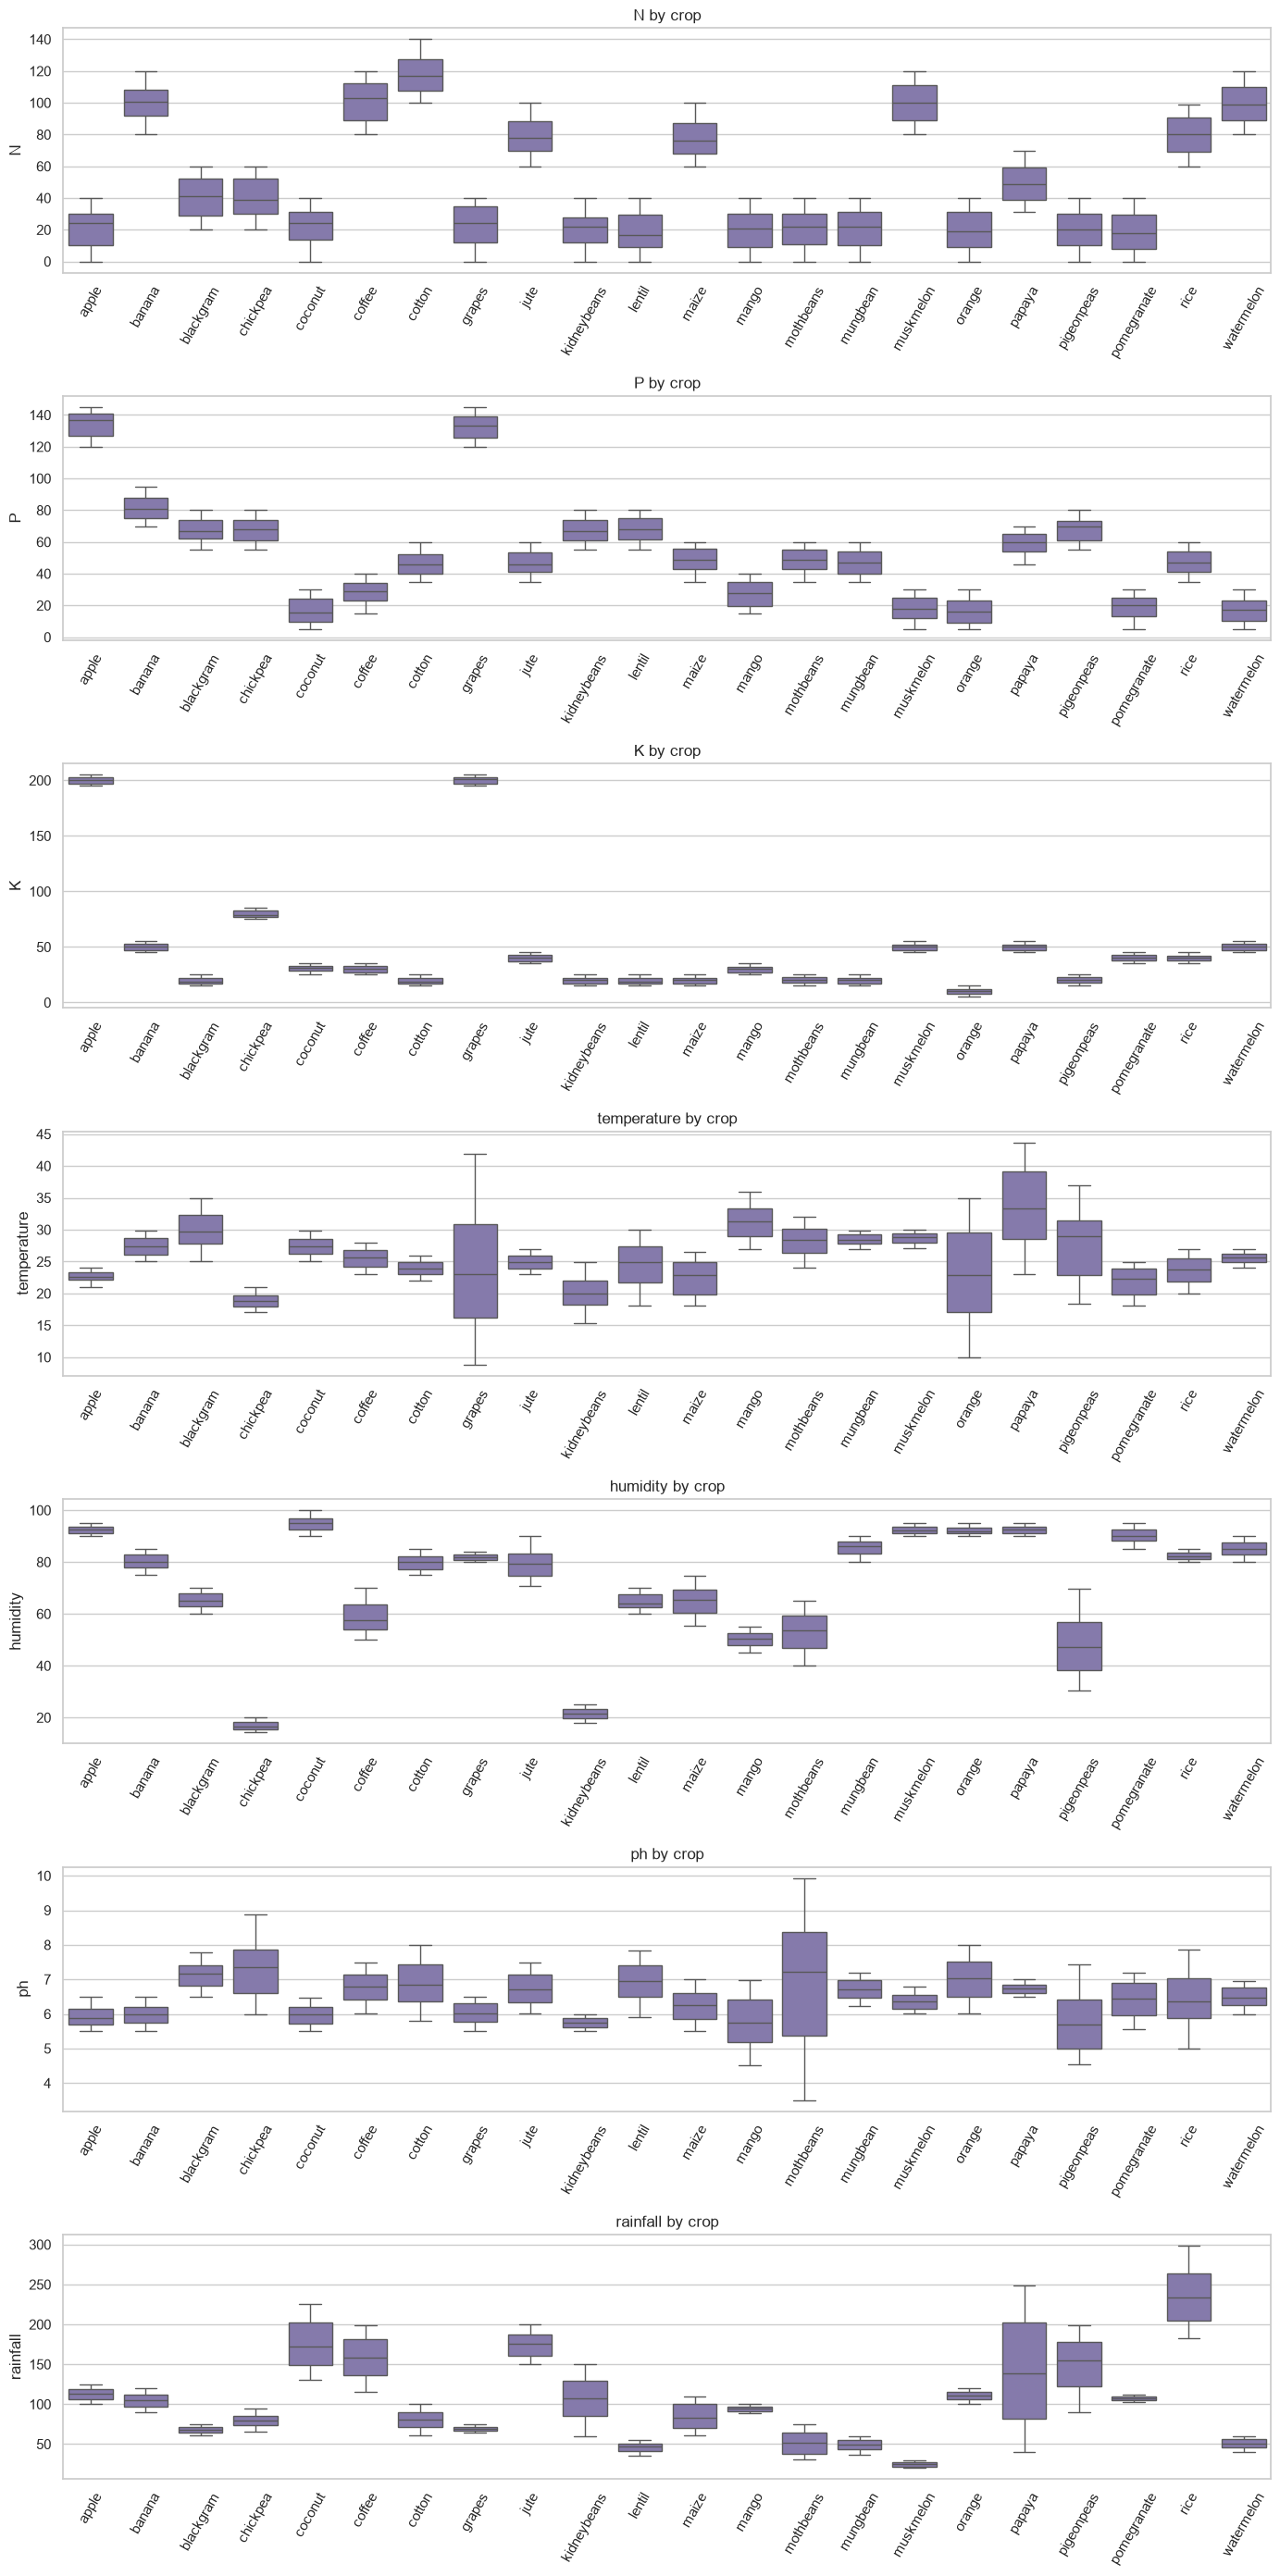

In [23]:
fig, axes = plt.subplots(len(FEATURES), 1, figsize=(14, 4 * len(FEATURES)))
order = sorted(df[TARGET].unique())
for ax, col in zip(axes, FEATURES):
    sns.boxplot(data=df, x=TARGET, y=col, order=order, ax=ax, color="#8172B3")
    ax.set_title(f"{col} by crop")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=60)
fig.tight_layout()
save_fig(fig, "06_features_by_crop_boxplots")
plt.show()

**Observation:** Many crops occupy narrow, distinct ranges:
- **Apple & grapes:** very high P (~130) and K (~200).
- **Rice:** highest rainfall (~236 mm); **coconut, jute** also high.
- **Chickpea & kidneybeans:** very dry (humidity ~17-22 %).
- **Cotton, coffee, banana, muskmelon, watermelon:** high N (~100-118).
- **Papaya, mango:** hottest (~31-34 °C); **chickpea** coolest (~19 °C).
- **pH** overlaps a lot between crops - it is likely the least discriminative feature.

### 7.3 Feature importance hint: how much does each feature vary between crops?
A simple check without training any model: the **ratio of between-crop variance to total variance**
(eta-squared). Close to 1 = the feature separates crops well; close to 0 = it does not.

Saved: results\figures\07_feature_separation_eta_squared.png


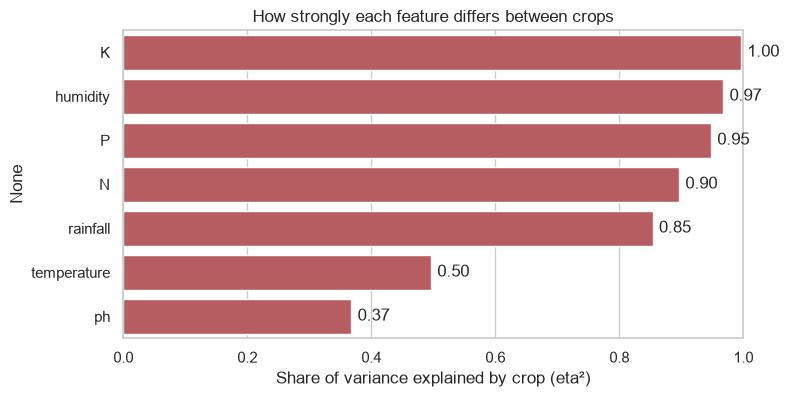

,eta_squared
K,1.00
humidity,0.97
P,0.95
N,0.90
rainfall,0.85
temperature,0.50
ph,0.37


In [24]:
def eta_squared(col):
    grand = df[col].mean()
    between = df.groupby(TARGET)[col].apply(lambda s: len(s) * (s.mean() - grand) ** 2).sum()
    total = ((df[col] - grand) ** 2).sum()
    return between / total

eta = pd.Series({c: eta_squared(c) for c in FEATURES}, name="eta_squared").sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=eta.values, y=eta.index, color="#C44E52", ax=ax)
ax.set_xlim(0, 1)
ax.set_xlabel("Share of variance explained by crop (eta²)")
ax.set_title("How strongly each feature differs between crops")
for i, v in enumerate(eta.values):
    ax.text(v + 0.01, i, f"{v:.2f}", va="center")
save_fig(fig, "07_feature_separation_eta_squared")
plt.show()
eta.round(3).to_frame()

### 7.4 Scatter plots of key feature pairs
Scatter plots show whether crops form separate clusters in 2D.

Saved: results\figures\08_scatter_key_feature_pairs.png


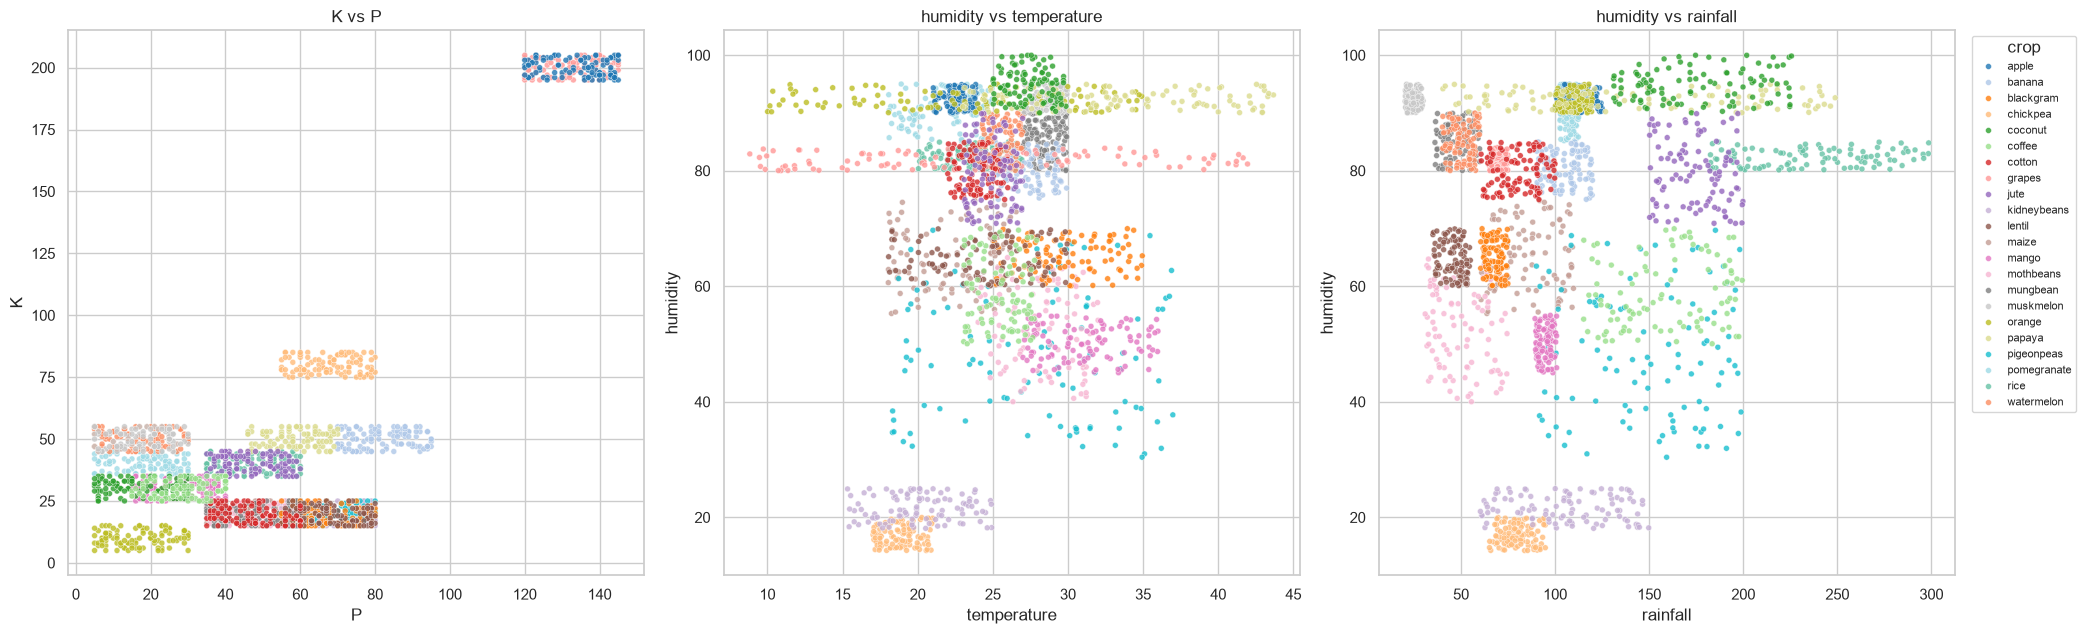

In [25]:
palette = sns.color_palette("tab20", 20) + sns.color_palette("Set2", 2)
fig, axes = plt.subplots(1, 3, figsize=(21, 6.5))
for ax, (x, y) in zip(axes, [("P", "K"), ("temperature", "humidity"), ("rainfall", "humidity")]):
    sns.scatterplot(data=df, x=x, y=y, hue=TARGET, hue_order=order, palette=palette, s=18, alpha=0.8, ax=ax, legend=(ax is axes[-1]))
    ax.set_title(f"{y} vs {x}")
axes[-1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8, ncol=1, title="crop")
fig.tight_layout()
save_fig(fig, "08_scatter_key_feature_pairs")
plt.show()

**Observation:** Clear clusters are visible - e.g. apple/grapes in the top-right of P-vs-K, chickpea and
kidneybeans in the low-humidity band. Some crops overlap in 2D (e.g. several pulses), but combining
all 7 features should separate them well.

**Note on data origin:** many crops form neat rectangular blocks (values spread evenly inside fixed
limits). This suggests the dataset was **synthetically generated or augmented** from per-crop ranges.
Expect very high model accuracy here; real farm data would be noisier.

### 7.5 Pair plot of all features (sampled crop groups)
To keep it readable, we show a pair plot for 6 representative crops.

Saved: results\figures\09_pairplot_sample_crops.png


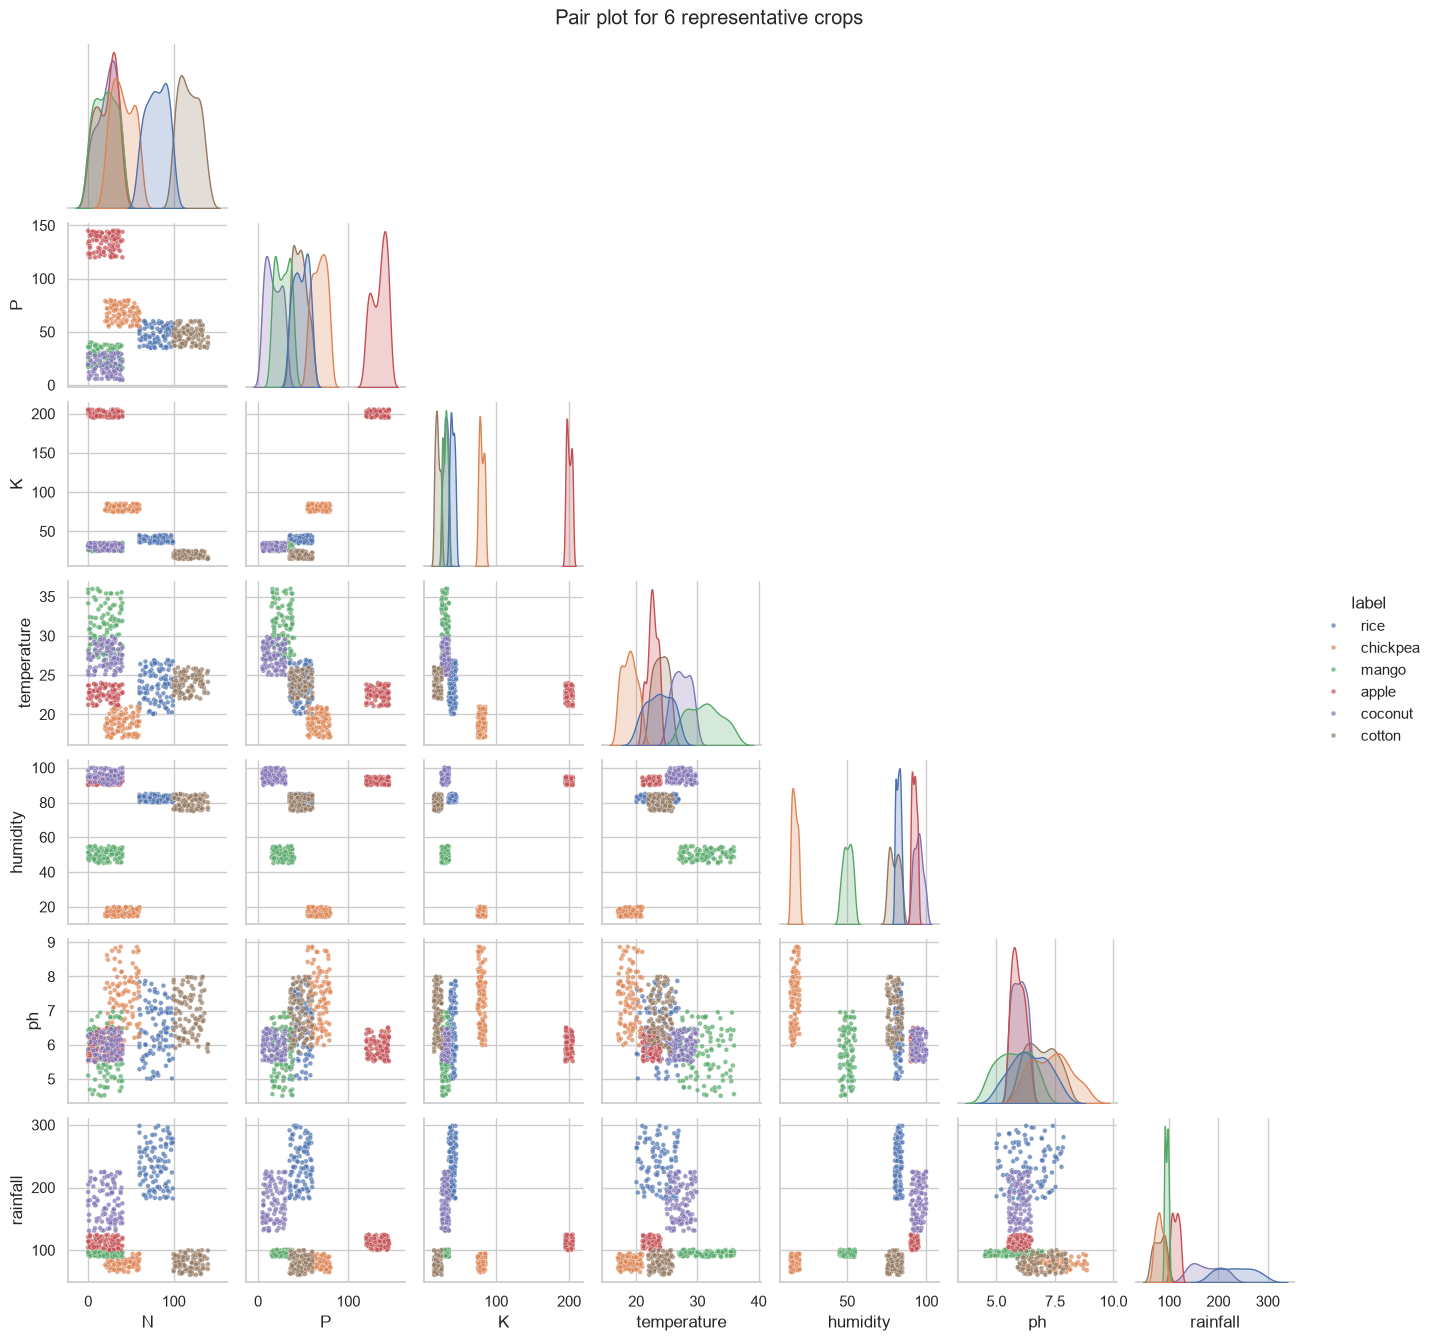

In [26]:
sample_crops = ["rice", "apple", "chickpea", "cotton", "mango", "coconut"]
g = sns.pairplot(df[df[TARGET].isin(sample_crops)], vars=FEATURES, hue=TARGET,
                 corner=True, plot_kws={"s": 12, "alpha": 0.7}, height=1.9)
g.fig.suptitle("Pair plot for 6 representative crops", y=1.01)
save_fig(g.fig, "09_pairplot_sample_crops")
plt.show()

## 8. Summary of findings
| Check | Result |
|---|---|
| Rows × columns | 2,200 × 8 (7 numeric features + 1 target) |
| Missing values | None |
| Duplicates | None |
| Invalid values | None |
| Target balance | 22 crops × 100 rows each (perfectly balanced) |
| Skewed features | K (strong), P, rainfall (moderate right), humidity (left) |
| Outliers (IQR) | Present but crop-specific and genuine - keep them |
| Strong correlation | Only P-K (r ≈ 0.74) |
| Most separating features | K, humidity, P, N, rainfall (eta² ≥ 0.85) |
| Weaker features | temperature (0.50), pH (0.37) - still useful in combination |

## 9. Recommendations for preprocessing (next phase)
1. **No cleaning needed** - no missing values, duplicates, or invalid rows.
2. **Keep outliers** - they are real crop characteristics.
3. **Encode the target** - convert crop names to numbers with `LabelEncoder` (and save the encoder to decode predictions).
4. **Stratified train/test split** (e.g. 80/20, `stratify=label`) to keep the 22 classes balanced in both sets.
5. **Feature scaling** (`StandardScaler`) for scale-sensitive models (Logistic Regression, KNN, SVM).
   Fit the scaler **only on training data** to avoid data leakage. Tree models (Decision Tree, Random Forest) do not need scaling.
6. **Keep all 7 features** - no redundancy severe enough to drop; P-K correlation is acceptable.
7. Optional: log-transform K / rainfall for linear models; not required for tree models.
8. **Metrics:** accuracy is fair because classes are balanced; also report per-class precision/recall/F1 and a confusion matrix.